Importing Libaries

In [ ]:
!pip -q install pymupdf pandas tqdm sentence-transformers faiss-cpu scikit-learn matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.0/25.0 MB 35.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 40.6 MB/s eta 0:00:00


In [ ]:
import os
import re
import json
import math
import time
import pickle
import numpy as np
import pandas as pd
import fitz
import faiss
import matplotlib.pyplot as plt

from tqdm import tqdm
from sentence_transformers import SentenceTransformer
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

In [ ]:
PDF_DIR = "/content/reports"
PARSED_DIR = "/content/parsed_reports"
CHUNKS_DIR = "/content/chunks"
RESULTS_DIR = "/content/results"
FAISS_DIR = "/content/faiss_index"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")

for d in [PDF_DIR, PARSED_DIR, CHUNKS_DIR, RESULTS_DIR, FAISS_DIR, FIG_DIR]:
    os.makedirs(d, exist_ok=True)

print("Folders ready.")

Folders ready.


Importing PDFs

In [ ]:
from google.colab import files

uploaded = files.upload()

for filename, data in uploaded.items():
    if filename.lower().endswith(".pdf"):
        with open(os.path.join(PDF_DIR, filename), "wb") as f:
            f.write(data)

print("Files in reports folder:", os.listdir(PDF_DIR))

Saving AngloAmerican_Report_2021.pdf to AngloAmerican_Report_2021.pdf
Saving AngloAmerican_Report_2022.pdf to AngloAmerican_Report_2022.pdf
Saving AngloAmerican_Report_2023.pdf to AngloAmerican_Report_2023.pdf
Saving AngloAmerican_Report_2024.pdf to AngloAmerican_Report_2024.pdf
Saving Antofagsata_Report_2021.pdf to Antofagsata_Report_2021.pdf
Saving Antofagsata_Report_2022.pdf to Antofagsata_Report_2022.pdf
Saving Antofagsata_Report_2023.pdf to Antofagsata_Report_2023.pdf
Saving Antofagsata_Report_2024.pdf to Antofagsata_Report_2024.pdf
Saving AshteadGroup_Report_2021.pdf to AshteadGroup_Report_2021.pdf
Saving AshteadGroup_Report_2022.pdf to AshteadGroup_Report_2022.pdf
Saving AshteadGroup_Report_2023.pdf to AshteadGroup_Report_2023.pdf
Saving AshteadGroup_Report_2024.pdf to AshteadGroup_Report_2024.pdf
Saving AstraZeneca_Report_2021.pdf to AstraZeneca_Report_2021.pdf
Saving AstraZeneca_Report_2022.pdf to AstraZeneca_Report_2022.pdf
Saving AstraZeneca_Report_2023.pdf to AstraZeneca_Re

Parsing

In [ ]:
def clean_text(text: str) -> str:
    text = text.replace("\x00", " ")
    text = re.sub(r"[ \t]+", " ", text)
    text = re.sub(r"\n{3,}", "\n\n", text)
    return text.strip()

def parse_pdf(pdf_path: str):
    doc = fitz.open(pdf_path)
    pages = []

    for page_num in range(len(doc)):
        page = doc[page_num]
        text = page.get_text("text")
        text = clean_text(text)
        pages.append({
            "page_num": page_num + 1,
            "text": text
        })

    full_text = "\n\n".join(
        [f"[PAGE {p['page_num']}]\n{p['text']}" for p in pages if p["text"].strip()]
    )

    return {
        "file_name": os.path.basename(pdf_path),
        "num_pages": len(doc),
        "pages": pages,
        "full_text": full_text
    }

In [ ]:
parsed_rows = []
pdf_files = sorted([f for f in os.listdir(PDF_DIR) if f.lower().endswith(".pdf")])
print(f"Found {len(pdf_files)} PDFs")

for pdf_file in tqdm(pdf_files):
    pdf_path = os.path.join(PDF_DIR, pdf_file)
    parsed = parse_pdf(pdf_path)

    base_name = os.path.splitext(pdf_file)[0]
    out_path = os.path.join(PARSED_DIR, f"{base_name}.json")

    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(parsed, f, ensure_ascii=False, indent=2)

    parsed_rows.append({
        "file_name": pdf_file,
        "num_pages": parsed["num_pages"],
        "chars_full_text": len(parsed["full_text"]),
        "json_path": out_path
    })

parsed_df = pd.DataFrame(parsed_rows)
parsed_df.to_csv(os.path.join(RESULTS_DIR, "parsing_summary.csv"), index=False)
parsed_df

Found 100 PDFs


 66%|██████▌   | 66/100 [00:50<00:25,  1.34it/s]

MuPDF error: format error: premature end in aes filter

MuPDF error: format error: premature end in aes filter

MuPDF error: format error: premature end in aes filter

MuPDF error: format error: premature end in aes filter

MuPDF error: format error: premature end in aes filter

MuPDF error: format error: premature end in aes filter



100%|██████████| 100/100 [01:05<00:00,  1.53it/s]


,file_name,num_pages,chars_full_text,json_path
0,AngloAmerican_Report_2021.pdf,38,160640,/content/parsed_reports/AngloAmerican_Report_2...
1,AngloAmerican_Report_2022.pdf,75,296541,/content/parsed_reports/AngloAmerican_Report_2...
2,AngloAmerican_Report_2023.pdf,88,323661,/content/parsed_reports/AngloAmerican_Report_2...
3,AngloAmerican_Report_2024.pdf,97,355804,/content/parsed_reports/AngloAmerican_Report_2...
4,Antofagsata_Report_2021.pdf,84,276448,/content/parsed_reports/Antofagsata_Report_202...
...,...,...,...,...
95,Unilever_Report_2024.pdf,37,188479,/content/parsed_reports/Unilever_Report_2024.json
96,Vodafone_Report_2021.pdf,48,277478,/content/parsed_reports/Vodafone_Report_2021.json
97,Vodafone_Report_2022.pdf,54,310764,/content/parsed_reports/Vodafone_Report_2022.json
98,Vodafone_Report_2023.pdf,46,276539,/content/parsed_reports/Vodafone_Report_2023.json


Chunking

In [ ]:
CHUNK_SIZE = 1200
CHUNK_OVERLAP = 200

def normalize_text(text: str) -> str:
    return re.sub(r"\s+", " ", text).strip()

def chunk_text(text, chunk_size=1200, overlap=200):
    text = normalize_text(text)
    chunks = []
    start = 0

    while start < len(text):
        end = start + chunk_size
        chunk = text[start:end].strip()
        if chunk:
            chunks.append(chunk)
        start += chunk_size - overlap

    return chunks

In [ ]:
all_chunks = []
chunk_summary = []

parsed_files = sorted([f for f in os.listdir(PARSED_DIR) if f.endswith(".json")])
print(f"Found {len(parsed_files)} parsed files")

for parsed_file in tqdm(parsed_files):
    parsed_path = os.path.join(PARSED_DIR, parsed_file)

    with open(parsed_path, "r", encoding="utf-8") as f:
        doc = json.load(f)

    file_name = doc["file_name"]
    base_name = os.path.splitext(file_name)[0]
    doc_chunks = []
    chunk_id = 0

    for page in doc["pages"]:
        page_num = page["page_num"]
        page_text = page["text"]

        if not page_text.strip():
            continue

        page_chunks = chunk_text(page_text, chunk_size=CHUNK_SIZE, overlap=CHUNK_OVERLAP)

        for chunk in page_chunks:
            record = {
                "chunk_id": f"{base_name}_chunk_{chunk_id}",
                "file_name": file_name,
                "company": base_name,
                "page_num": page_num,
                "text": chunk
            }
            doc_chunks.append(record)
            all_chunks.append(record)
            chunk_id += 1

    out_path = os.path.join(CHUNKS_DIR, f"{base_name}_chunks.json")
    with open(out_path, "w", encoding="utf-8") as f:
        json.dump(doc_chunks, f, ensure_ascii=False, indent=2)

    chunk_summary.append({
        "file_name": file_name,
        "num_chunks": len(doc_chunks)
    })

chunks_df = pd.DataFrame(all_chunks)
chunk_summary_df = pd.DataFrame(chunk_summary)

chunks_df.to_csv(os.path.join(RESULTS_DIR, "all_chunks.csv"), index=False)
chunk_summary_df.to_csv(os.path.join(RESULTS_DIR, "chunk_summary.csv"), index=False)

print("Total chunks:", len(chunks_df))
chunks_df.head()

Found 100 parsed files


100%|██████████| 100/100 [00:03<00:00, 32.32it/s]


Total chunks: 30064


,chunk_id,file_name,company,page_num,text
0,AngloAmerican_Report_2021_chunk_0,AngloAmerican_Report_2021.pdf,AngloAmerican_Report_2021,1,68 Anglo American plc Integrated Annual Report...
1,AngloAmerican_Report_2021_chunk_1,AngloAmerican_Report_2021.pdf,AngloAmerican_Report_2021,1,17.7 16.2 Measured in million m3 2021 2020 201...
2,AngloAmerican_Report_2021_chunk_2,AngloAmerican_Report_2021.pdf,AngloAmerican_Report_2021,1,.5 2.8 2019 2018 2.9 2.9 Women in management (...
3,AngloAmerican_Report_2021_chunk_3,AngloAmerican_Report_2021.pdf,AngloAmerican_Report_2021,2,69 Anglo American plc Integrated Annual Report...
4,AngloAmerican_Report_2021_chunk_4,AngloAmerican_Report_2021.pdf,AngloAmerican_Report_2021,2,zil – $/tonne (wet basis) 2021 2020 2019 2018 ...


Embeddings + FAISS

In [ ]:
EMBED_MODEL_NAME = "sentence-transformers/all-MiniLM-L6-v2"
embed_model = SentenceTransformer(EMBED_MODEL_NAME)

chunk_texts = chunks_df["text"].fillna("").tolist()
embeddings = embed_model.encode(
    chunk_texts,
    batch_size=32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print("Embeddings shape:", embeddings.shape)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

...

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/940 [00:00<?, ?it/s]

Embeddings shape: (30064, 384)


In [ ]:
embedding_dim = embeddings.shape[1]
index = faiss.IndexFlatIP(embedding_dim)
index.add(embeddings.astype("float32"))

faiss.write_index(index, os.path.join(FAISS_DIR, "chunks.index"))

with open(os.path.join(FAISS_DIR, "chunks_metadata.pkl"), "wb") as f:
    pickle.dump(chunks_df.to_dict(orient="records"), f)

print("FAISS index saved")
print("Total vectors in index:", index.ntotal)

FAISS index saved
Total vectors in index: 30064


Hybrid Retrieval Index

In [ ]:
index = faiss.read_index(os.path.join(FAISS_DIR, "chunks.index"))
with open(os.path.join(FAISS_DIR, "chunks_metadata.pkl"), "rb") as f:
    metadata = pickle.load(f)

def retrieve_chunks(query, top_k=5):
    query_emb = embed_model.encode(
        [query],
        convert_to_numpy=True,
        normalize_embeddings=True
    ).astype("float32")

    scores, indices = index.search(query_emb, top_k)

    results = []
    for score, idx in zip(scores[0], indices[0]):
        row = metadata[idx]
        results.append({
            "score": float(score),
            "chunk_id": row["chunk_id"],
            "file_name": row["file_name"],
            "company": row["company"],
            "page_num": int(row["page_num"]),
            "text": row["text"]
        })
    return results

def build_context(retrieved_chunks):
    # cleaner prompt context; no [Chunk x] labels
    return "\n\n".join([r["text"] for r in retrieved_chunks])

In [ ]:
ESG_QUERIES = {
    "E1": "What is the reported global total Scope 1 greenhouse gas emissions value? Include the numeric value and unit (e.g., tonnes CO2e).",
    "E2": "What is the reported global total Scope 2 (if both market and location based are included, select location-based) greenhouse gas emissions value? Include the numeric value and unit (e.g., tonnes CO2e).",
    "E3": "What is the reported global total Scope 3 greenhouse gas emissions value? Include the numeric value and unit (e.g., tonnes CO2e).",
    "E4": "What is the total energy consumption reported by the company? Include the numeric value and unit (e.g., GWh or GJ).",
    "E5": "What is the reported total water withdrawal or water consumption value? Include the numeric value and unit.",
    "E6": "What is the reported total hazardous waste generated? Include the numeric value and unit."
}

In [ ]:
retrieval_rows = []

for query_id, query_text in ESG_QUERIES.items():
    results = retrieve_chunks(query_text, top_k=5)
    for rank, r in enumerate(results, 1):
        retrieval_rows.append({
            "query_id": query_id,
            "query": query_text,
            "rank": rank,
            "score": r["score"],
            "chunk_id": r["chunk_id"],
            "file_name": r["file_name"],
            "company": r["company"],
            "page_num": r["page_num"],
            "text": r["text"]
        })

retrieval_df = pd.DataFrame(retrieval_rows)
retrieval_df.to_csv(os.path.join(RESULTS_DIR, "retrieval_results.csv"), index=False)
retrieval_df.head(10)

,query_id,query,rank,score,chunk_id,file_name,company,page_num,text
0,E1,What is the reported global total Scope 1 gree...,1,0.762297,Unilever_Report_2024_chunk_81,Unilever_Report_2024.pdf,Unilever_Report_2024,15,"Gross Scope 1, 2 and 3, and total GHG emission..."
1,E1,What is the reported global total Scope 1 gree...,2,0.717992,RollsRoyceHoldings_Report_2023_chunk_63,RollsRoyceHoldings_Report_2023.pdf,RollsRoyceHoldings_Report_2023,13,"In 2023, our total gross Scope 1 + 2 greenhous..."
2,E1,What is the reported global total Scope 1 gree...,3,0.709691,Vodafone_Report_2023_chunk_293,Vodafone_Report_2023.pdf,Vodafone_Report_2023,46,ssions (million tonnes CO2e)2 0.69 0.00 0% 0.7...
3,E1,What is the reported global total Scope 1 gree...,4,0.709629,Experian_Report_2023_chunk_270,Experian_Report_2023.pdf,Experian_Report_2023,62,"3 figures using the same methodology, to provi..."
4,E1,What is the reported global total Scope 1 gree...,5,0.699128,Shell_Report_2021_chunk_70,Shell_Report_2021.pdf,Shell_Report_2021,25,Absolute emissions reduction performance In 20...
5,E2,What is the reported global total Scope 2 (if ...,1,0.765833,Unilever_Report_2024_chunk_81,Unilever_Report_2024.pdf,Unilever_Report_2024,15,"Gross Scope 1, 2 and 3, and total GHG emission..."
6,E2,What is the reported global total Scope 2 (if ...,2,0.751684,Experian_Report_2023_chunk_270,Experian_Report_2023.pdf,Experian_Report_2023,62,"3 figures using the same methodology, to provi..."
7,E2,What is the reported global total Scope 2 (if ...,3,0.751248,RollsRoyceHoldings_Report_2023_chunk_63,RollsRoyceHoldings_Report_2023.pdf,RollsRoyceHoldings_Report_2023,13,"In 2023, our total gross Scope 1 + 2 greenhous..."
8,E2,What is the reported global total Scope 2 (if ...,4,0.737606,Vodafone_Report_2023_chunk_293,Vodafone_Report_2023.pdf,Vodafone_Report_2023,46,ssions (million tonnes CO2e)2 0.69 0.00 0% 0.7...
9,E2,What is the reported global total Scope 2 (if ...,5,0.734658,Experian_Report_2022_chunk_281,Experian_Report_2022.pdf,Experian_Report_2022,69,CO2e¹ Unit 2022 20215 2020 2019 Scope 1 000s t...


# Experiments
**Open Model**
* Experiment 1 – Qwen2.5-1.5B-Instruct Prompt Baseline
* Experiment 2 – Qwen2.5-1.5B-Instruct Retrieval-Augmented Generation

**Closed Model**
* Experiment 3 – GPT 4.0 Prompt Baseline
 * Experiment 4 – GPT 4.0 Retrieval-Augmented Generation




1. Open model (Qwen2.5-1.5B-Instruct)

In [ ]:
from transformers import pipeline

qwen_pipe = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-1.5B-Instruct",
    device_map="auto"
)

def ask_qwen(query, context):
    # honest prompt baseline
    if not context.strip():
        return "NOT FOUND"

    prompt = f"""You are extracting ESG metrics from a company report.

Use ONLY the provided context.
Return ONLY:
- the final numeric value with unit
- or NOT FOUND

Examples:
9.0 Mt CO2e
5.7 Mt CO2e
20.9 million m3
85.0 million GJ
NOT FOUND

Question: {query}

Context:
{context}
"""
    result = qwen_pipe(
        prompt,
        max_new_tokens=16,
        do_sample=False,
        return_full_text=False,
        pad_token_id=qwen_pipe.tokenizer.eos_token_id
    )

    answer = result[0]["generated_text"].strip()
    answer = answer.replace("</s>", "").strip()
    answer = answer.split("\n")[0].strip()
    answer = answer.replace("Final answer:", "").replace("Answer:", "").strip()

    if not answer:
        return "NOT FOUND"
    if len(answer) > 60:
        return "NOT FOUND"

    return answer

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [ ]:
open_experiments = [
    {"id": "open_prompt", "model": "Qwen2.5-1.5B-Instruct", "method": "prompt"},
    {"id": "open_rag", "model": "Qwen2.5-1.5B-Instruct", "method": "rag"},
]

open_results = []

for exp in open_experiments:
    print(f"Running {exp['id']}...")
    for query_id, query in ESG_QUERIES.items():
        print(f"  {query_id}...")

        retrieved_pages = ""
        top_retrieval_score = None
        context = ""

        if exp["method"] == "rag":
            retrieved = retrieve_chunks(query, top_k=5)
            context = build_context(retrieved)
            retrieved_pages = ",".join(str(r["page_num"]) for r in retrieved)
            top_retrieval_score = retrieved[0]["score"] if retrieved else None

        start = time.time()
        answer = ask_qwen(query, context)
        latency_sec = time.time() - start

        open_results.append({
            "experiment": exp["id"],
            "model": exp["model"],
            "method": exp["method"],
            "query_id": query_id,
            "query": query,
            "answer": answer,
            "retrieved_pages": retrieved_pages,
            "top_retrieval_score": top_retrieval_score,
            "latency_sec": latency_sec
        })

open_results_df = pd.DataFrame(open_results)
open_results_df.to_csv(os.path.join(RESULTS_DIR, "open_experiment_results.csv"), index=False)
open_results_df

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.
Passing `generation_config` together with generation-related arguments=({'do_sample', 'pad_token_id', 'max_new_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Running open_prompt...
  E1...
  E2...
  E3...
  E4...
  E5...
  E6...
Running open_rag...
  E1...


Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  E2...


Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


...

Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  E5...


Both `max_new_tokens` (=16) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


  E6...


,experiment,model,method,query_id,query,answer,retrieved_pages,top_retrieval_score,latency_sec
0,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E1,What is the reported global total Scope 1 gree...,NOT FOUND,,NaN,3.337860e-06
1,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E2,What is the reported global total Scope 2 (if ...,NOT FOUND,,NaN,1.668930e-06
2,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E3,What is the reported global total Scope 3 gree...,NOT FOUND,,NaN,7.152557e-07
3,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E4,What is the total energy consumption reported ...,NOT FOUND,,NaN,9.536743e-07
4,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E5,What is the reported total water withdrawal or...,NOT FOUND,,NaN,9.536743e-07
5,open_prompt,Qwen2.5-1.5B-Instruct,prompt,E6,What is the reported total hazardous waste gen...,NOT FOUND,,NaN,4.768372e-07
6,open_rag,Qwen2.5-1.5B-Instruct,rag,E1,What is the reported global total Scope 1 gree...,NOT FOUND,"15,13,46,62,25",0.762297,7.259762e+02
7,open_rag,Qwen2.5-1.5B-Instruct,rag,E2,What is the reported global total Scope 2 (if ...,The final numeric value with unit is **14.7** ...,"15,62,13,46,69",0.765833,8.881673e+02
8,open_rag,Qwen2.5-1.5B-Instruct,rag,E3,What is the reported global total Scope 3 gree...,NOT FOUND,"15,62,46,67,13",0.757171,7.345798e+02
9,open_rag,Qwen2.5-1.5B-Instruct,rag,E4,What is the total energy consumption reported ...,"The final numeric value with unit is 2,602 GWh.","32,21,114,27,32",0.725220,6.267772e+02


2. Closed model (gpt-4o-mini)

In [ ]:
import os
# os.environ["OPENAI_API_KEY"] = "sk-XXX"

In [ ]:
from openai import OpenAI

# OpenAI API key removed from code to unauthorized usage
client = OpenAI(api_key="sk-XXX")

def ask_gpt(query, context):
    if not context.strip():
        return "NOT FOUND"

    prompt = f"""You are extracting ESG metrics from a company report.

Use ONLY the provided context.
Return ONLY:
- the final numeric value with unit
- or NOT FOUND

Examples:
9.0 Mt CO2e
5.7 Mt CO2e
20.9 million m3
85.0 million GJ
NOT FOUND

Question: {query}

Context:
{context}
"""
    response = client.chat.completions.create(
        model="gpt-4o-mini",
        messages=[{"role": "user", "content": prompt}],
        temperature=0
    )

    answer = response.choices[0].message.content.strip()
    answer = answer.split("\n")[0].strip()
    answer = answer.replace("Final answer:", "").replace("Answer:", "").strip()

    if not answer:
        return "NOT FOUND"
    if len(answer) > 60:
        return "NOT FOUND"

    return answer

In [ ]:
closed_experiments = [
    {"id": "closed_prompt", "model": "gpt-4o-mini", "method": "prompt"},
    {"id": "closed_rag", "model": "gpt-4o-mini", "method": "rag"},
]

closed_results = []

for exp in closed_experiments:
    print(f"Running {exp['id']}...")
    for query_id, query in ESG_QUERIES.items():
        print(f"  {query_id}...")

        retrieved_pages = ""
        top_retrieval_score = None
        context = ""

        if exp["method"] == "rag":
            retrieved = retrieve_chunks(query, top_k=5)
            context = build_context(retrieved)
            retrieved_pages = ",".join(str(r["page_num"]) for r in retrieved)
            top_retrieval_score = retrieved[0]["score"] if retrieved else None

        start = time.time()
        answer = ask_gpt(query, context)
        latency_sec = time.time() - start

        closed_results.append({
            "experiment": exp["id"],
            "model": exp["model"],
            "method": exp["method"],
            "query_id": query_id,
            "query": query,
            "answer": answer,
            "retrieved_pages": retrieved_pages,
            "top_retrieval_score": top_retrieval_score,
            "latency_sec": latency_sec
        })

closed_results_df = pd.DataFrame(closed_results)
closed_results_df.to_csv(os.path.join(RESULTS_DIR, "closed_experiment_results.csv"), index=False)
closed_results_df

Running closed_prompt...
  E1...
  E2...
  E3...
  E4...
  E5...
  E6...
Running closed_rag...
  E1...
  E2...
  E3...
  E4...
  E5...
  E6...


,experiment,model,method,query_id,query,answer,retrieved_pages,top_retrieval_score,latency_sec
0,closed_prompt,gpt-4o-mini,prompt,E1,What is the reported global total Scope 1 gree...,NOT FOUND,,NaN,5.722046e-06
1,closed_prompt,gpt-4o-mini,prompt,E2,What is the reported global total Scope 2 (if ...,NOT FOUND,,NaN,1.430511e-06
2,closed_prompt,gpt-4o-mini,prompt,E3,What is the reported global total Scope 3 gree...,NOT FOUND,,NaN,7.152557e-07
3,closed_prompt,gpt-4o-mini,prompt,E4,What is the total energy consumption reported ...,NOT FOUND,,NaN,4.768372e-07
4,closed_prompt,gpt-4o-mini,prompt,E5,What is the reported total water withdrawal or...,NOT FOUND,,NaN,7.152557e-07
5,closed_prompt,gpt-4o-mini,prompt,E6,What is the reported total hazardous waste gen...,NOT FOUND,,NaN,4.768372e-07
6,closed_rag,gpt-4o-mini,rag,E1,What is the reported global total Scope 1 gree...,"109,257 tonnes CO2e","15,13,46,62,25",0.762297,3.815058e+00
7,closed_rag,gpt-4o-mini,rag,E2,What is the reported global total Scope 2 (if ...,"88,504 tonnes CO2e","15,62,13,46,69",0.765833,5.092726e-01
8,closed_rag,gpt-4o-mini,rag,E3,What is the reported global total Scope 3 gree...,NOT FOUND,"15,62,46,67,13",0.757171,1.755814e+00
9,closed_rag,gpt-4o-mini,rag,E4,What is the total energy consumption reported ...,"2,627,262 MWh","32,21,114,27,32",0.725220,5.597358e-01


In [ ]:
#combining results table for evaluation

combined_results_df = pd.concat([open_results_df, closed_results_df], ignore_index=True)
combined_results_df.to_csv(os.path.join(RESULTS_DIR, "combined_experiment_results.csv"), index=False)

combined_report_table = combined_results_df.pivot_table(
    index="query_id",
    columns="experiment",
    values=["answer", "retrieved_pages"],
    aggfunc="first"
)

combined_report_table.columns = [f"{col[1]}_{col[0]}" for col in combined_report_table.columns]
combined_report_table = combined_report_table.reset_index()

combined_report_table.to_csv(os.path.join(RESULTS_DIR, "final_results_with_pages.csv"), index=False)
combined_report_table

,query_id,closed_prompt_answer,closed_rag_answer,open_prompt_answer,open_rag_answer,closed_prompt_retrieved_pages,closed_rag_retrieved_pages,open_prompt_retrieved_pages,open_rag_retrieved_pages
0,E1,NOT FOUND,"109,257 tonnes CO2e",NOT FOUND,NOT FOUND,,"15,13,46,62,25",,"15,13,46,62,25"
1,E2,NOT FOUND,"88,504 tonnes CO2e",NOT FOUND,The final numeric value with unit is **14.7** ...,,"15,62,13,46,69",,"15,62,13,46,69"
2,E3,NOT FOUND,NOT FOUND,NOT FOUND,NOT FOUND,,"15,62,46,67,13",,"15,62,46,67,13"
3,E4,NOT FOUND,"2,627,262 MWh",NOT FOUND,"The final numeric value with unit is 2,602 GWh.",,"32,21,114,27,32",,"32,21,114,27,32"
4,E5,NOT FOUND,NOT FOUND,NOT FOUND,9.0 Mt CO2e,,"95,42,42,53,24",,"95,42,42,53,24"
5,E6,NOT FOUND,25 metric tonnes,NOT FOUND,NOT FOUND,,"116,68,32,116,116",,"116,68,32,116,116"


Evaluation

In [ ]:
ground_truth_df = pd.read_csv("/content/ground_truth .csv", encoding="latin1")
ground_truth_df.head()

,report_id,query_id,answer_text,numeric_value,unit,page_num,secondary_page_num,notes
0,AngloAmerican_Report_2021,E1,Scope 1 emissions  Global 9.0 Measured in Mt ...,9.00,Mt CO2e,104,NaN,NaN
1,AngloAmerican_Report_2021,E2,Scope 2 emissions  Global 5.7 Measured in Mt ...,5.70,Mt CO2e,104,NaN,NaN
2,AngloAmerican_Report_2021,E3,Scope 3 emissions for the year ended 31 Decemb...,NOT FOUND,Mt CO2e,104,NaN,NaN
3,AngloAmerican_Report_2021,E4,Energy use  Global** 85 Measured in million GJ,85.00,million GJ,104,NaN,NaN
4,AngloAmerican_Report_2021,E5,Total Water Withdrawals. Target: Reduce the wi...,177.00,million m3,68,NaN,NaN


In [1]:
# functions to clean text, pull out numbers/units and check if answers are correct

def normalize_text(s):
    # clean text
    if s is None:
        return ""
    s = str(s).strip().lower()
    s = s.replace("final answer:", "").replace("answer:", "").strip()
    s = re.sub(r"\\*\\*", "", s)
    s = re.sub(r"\\s+", " ", s)
    return s

def sanitize_numeric_string(s):
    #  removes commas from numbers in text --> actual numbers.
    if s is None:
        return None
    return str(s).replace(",", "")

def is_not_found(answer):
    #  'N/A' or empty
    a = normalize_text(answer)
    return a in {"not found", "n/a", "na", "none", ""}

def extract_first_number(text):
    #  pull out first number
    if text is None:
        return None
    text = sanitize_numeric_string(text)
    m = re.search(r"[-+]?\\d*\\.?\\d+", text)
    return float(m.group()) if m else None

def extract_unit(text):
    # common units and finds first one
    if text is None:
        return None
    text = sanitize_numeric_string(text)
    text = normalize_text(text)

    patterns = [
        r"(mt co2e)",
        r"(tonnes co2e)",
        r"(tco2e)",
        r"(million gj)",
        r"(gj)",
        r"(gwh)",
        r"(mwh)",
        r"(kwh)",
        r"(million m3)",
        r"(m3)",
        r"(tonnes)",
        r"(kg)",
        r"(%)"
    ]

    for p in patterns:
        m = re.search(p, text)
        if m:
            return m.group(1)
    return None

def numeric_match(pred, true_value, rel_tol=0.02, abs_tol=1e-6):
    # compares predicted number and true number
    # handles not found
    pred_value = extract_first_number(pred)

    if pd.isna(true_value):
        # if correct answer = missing, check if the prediction is also 'NOT FOUND'.
        return int(is_not_found(pred))

    # cleans true value
    sanitized_true_value = sanitize_numeric_string(true_value)

    # true value='NOT FOUND', prediction = 'NOT FOUND'.
    if is_not_found(sanitized_true_value):
        return int(is_not_found(pred))

    try:
        #true value ---> real number.
        true_float_value = float(sanitized_true_value)
    except ValueError:
        return 0

    if pred_value is None:
        return 0


    return int(math.isclose(pred_value, true_float_value, rel_tol=rel_tol, abs_tol=abs_tol))

def unit_match(pred, true_unit):
    # unit extracted = correct unit?
    if pd.isna(true_unit)
        return int(is_not_found(pred))
    pred_unit = extract_unit(pred)
    if pred_unit is None:

        return 0

    return int(normalize_text(pred_unit) == normalize_text(true_unit))

def exact_answer_match(pred, true_answer):
    return int(normalize_text(pred) == normalize_text(true_answer))

def disclosure_pred(answer):
    return 0 if is_not_found(answer) else 1

In [ ]:
ground_truth_df["is_disclosed"] = ground_truth_df["answer_text"].apply(disclosure_pred)

def extract_and_combine_pages(row):
    pages = []
    if pd.notna(row["page_num"]):
        pages.extend([int(n) for n in re.findall(r"\d+", str(row["page_num"]))])
    if "secondary_page_num" in row and pd.notna(row["secondary_page_num"]):
        pages.extend([int(n) for n in re.findall(r"\d+", str(row["secondary_page_num"]))])
    return sorted(list(set(pages)))

ground_truth_df["ground_truth_pages"] = ground_truth_df.apply(extract_and_combine_pages, axis=1)
ground_truth_df[["query_id", "ground_truth_pages"]]

,query_id,ground_truth_pages
0,E1,[104]
1,E2,[104]
2,E3,[104]
3,E4,[104]
4,E5,[68]
...,...,...
619,E2,[39]
620,E3,[7]
621,E4,[7]
622,E5,[]


In [ ]:
USE_PAGE_METRICS = False  # change to True only after page numbers are aligned

In [ ]:
def page_hit(retrieved_pages_str, gt_pages):
    if retrieved_pages_str is None or str(retrieved_pages_str).strip() == "":
        return 0

    retrieved = set()
    for p in str(retrieved_pages_str).split(","):
        p = p.strip()
        if p.isdigit():
            retrieved.add(int(p))

    return int(any(p in retrieved for p in gt_pages))

def reciprocal_rank_from_pages(retrieved_pages_str, gt_pages):
    if retrieved_pages_str is None or str(retrieved_pages_str).strip() == "":
        return 0.0

    ranked_pages = []
    for p in str(retrieved_pages_str).split(","):
        p = p.strip()
        if p.isdigit():
            ranked_pages.append(int(p))

    for i, page in enumerate(ranked_pages, start=1):
        if page in gt_pages:
            return 1.0 / i
    return 0.0

In [ ]:
eval_df = combined_results_df.merge(
    ground_truth_df,
    on="query_id",
    how="left"
)

print("Actual rows:", len(eval_df))
print(eval_df[["experiment", "query_id"]].value_counts().sort_index())

Actual rows: 2400
experiment     query_id
closed_prompt  E1          100
               E2          100
               E3          100
               E4          100
               E5          100
               E6          100
closed_rag     E1          100
               E2          100
               E3          100
               E4          100
               E5          100
               E6          100
open_prompt    E1          100
               E2          100
               E3          100
               E4          100
               E5          100
               E6          100
open_rag       E1          100
               E2          100
               E3          100
               E4          100
               E5          100
               E6          100
Name: count, dtype: int64


In [ ]:
eval_df["pred_is_disclosed"] = eval_df["answer"].apply(disclosure_pred)
eval_df["exact_match"] = eval_df.apply(lambda r: exact_answer_match(r["answer"], r["answer_text"]), axis=1)
eval_df["numeric_match"] = eval_df.apply(lambda r: numeric_match(r["answer"], r["numeric_value"]), axis=1)
eval_df["unit_match"] = eval_df.apply(lambda r: unit_match(r["answer"], r["unit"]), axis=1)

if USE_PAGE_METRICS:
    eval_df["page_hit_at_k"] = eval_df.apply(lambda r: page_hit(r["retrieved_pages"], r["ground_truth_pages"]), axis=1)
    eval_df["mrr"] = eval_df.apply(lambda r: reciprocal_rank_from_pages(r["retrieved_pages"], r["ground_truth_pages"]), axis=1)
else:
    eval_df["page_hit_at_k"] = np.nan
    eval_df["mrr"] = np.nan

eval_df["full_extraction_correct"] = (
    (eval_df["pred_is_disclosed"] == eval_df["is_disclosed"]) &
    (eval_df["numeric_match"] == 1) &
    (
        eval_df["unit"].isna() |
        (eval_df["unit_match"] == 1)
    )
).astype(int)

eval_df[[
    "experiment", "query_id", "answer_text", "answer",
    "is_disclosed", "pred_is_disclosed",
    "numeric_match", "unit_match", "full_extraction_correct"
]]

,experiment,query_id,answer_text,answer,is_disclosed,pred_is_disclosed,numeric_match,unit_match,full_extraction_correct
0,open_prompt,E1,Scope 1 emissions  Global 9.0 Measured in Mt ...,NOT FOUND,1,0,0,0,0
1,open_prompt,E1,Scope 1 emissions 2022 8.3Mt CO2e,NOT FOUND,1,0,0,0,0
2,open_prompt,E1,Scope 1 emissions 2023 7.5Mt CO2e,NOT FOUND,1,0,0,0,0
3,open_prompt,E1,Scope 1 emissions 2024 6.7 Mt CO2e,NOT FOUND,1,0,0,0,0
4,open_prompt,E1,"Scope 1, direct emissions Tonnes CO2 equivalen...",NOT FOUND,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...
2395,closed_rag,E6,NOT FOUND,25 metric tonnes,0,1,0,0,0
2396,closed_rag,E6,"Total network waste (metric tonnes) 6,307",25 metric tonnes,1,1,0,0,0
2397,closed_rag,E6,Total waste (including hazardous waste) metric...,25 metric tonnes,1,1,0,0,0
2398,closed_rag,E6,Total network waste (including hazardous waste...,25 metric tonnes,1,1,0,0,0


Evaluation Metrics

In [ ]:
def specificity_score(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return tn / (tn + fp) if (tn + fp) > 0 else np.nan

summary_rows = []

for exp, g in eval_df.groupby("experiment"):
    y_true = g["is_disclosed"].astype(int)
    y_pred = g["pred_is_disclosed"].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()

    summary_rows.append({
        "experiment": exp,
        "n_queries": len(g),
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "accuracy": accuracy_score(y_true, y_pred),
        "precision": precision_score(y_true, y_pred, zero_division=0),
        "sensitivity_recall": recall_score(y_true, y_pred, zero_division=0),
        "specificity": specificity_score(y_true, y_pred),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "exact_match_rate": g["exact_match"].mean(),
        "numeric_match_rate": g["numeric_match"].mean(),
        "unit_match_rate": g["unit_match"].mean(),
        "retrieval_hit_rate": g["page_hit_at_k"].mean(),
        "mrr": g["mrr"].mean(),
        "avg_latency_sec": g["latency_sec"].mean()
    })

summary_df = pd.DataFrame(summary_rows)
summary_df.sort_values("f1", ascending=False)

,experiment,n_queries,TP,TN,FP,FN,accuracy,precision,sensitivity_recall,specificity,f1,exact_match_rate,numeric_match_rate,unit_match_rate,retrieval_hit_rate,mrr,avg_latency_sec
1,closed_rag,600,278,81,122,119,0.598333,0.695,0.700252,0.399015,0.697616,0.135000,0.138333,0.081667,NaN,NaN,1.278010
3,open_rag,600,195,98,105,202,0.488333,0.650,0.491184,0.482759,0.559541,0.163333,0.168333,0.031667,NaN,NaN,647.617663
0,closed_prompt,600,0,203,0,397,0.338333,0.000,0.000000,1.000000,0.000000,0.338333,0.346667,0.003333,NaN,NaN,0.000002
2,open_prompt,600,0,203,0,397,0.338333,0.000,0.000000,1.000000,0.000000,0.338333,0.346667,0.003333,NaN,NaN,0.000001


Error Analysis

In [ ]:
def classify_error(row):
    gt_disclosed = row["is_disclosed"]
    pred_disclosed = row["pred_is_disclosed"]
    numeric_ok = row["numeric_match"]
    unit_ok = row["unit_match"]
    retrieval_ok = row["page_hit_at_k"] if not pd.isna(row["page_hit_at_k"]) else None
    answer = str(row["answer"]).lower()

    if row["full_extraction_correct"] == 1:
        return "correct"

    if gt_disclosed == 1 and pred_disclosed == 0:
        return "missed_disclosure"

    if gt_disclosed == 0 and pred_disclosed == 1:
        return "false_positive"

    if retrieval_ok == 0 and gt_disclosed == 1:
        return "retrieval_failure"

    if numeric_ok == 0 and gt_disclosed == 1:
        return "wrong_value"

    if unit_ok == 0 and gt_disclosed == 1:
        return "wrong_unit"

    if "not found" not in answer and retrieval_ok == 0:
        return "hallucination"

    if len(answer) > 50:
        return "formatting_error"

    return "other"

eval_df["error_type"] = eval_df.apply(classify_error, axis=1)

In [ ]:
error_summary = (
    eval_df.groupby(["experiment", "error_type"])
    .size()
    .reset_index(name="count")
)

error_summary["percentage"] = (
    error_summary.groupby("experiment")["count"]
    .transform(lambda x: x / x.sum())
)

error_pivot = error_summary.pivot(
    index="error_type",
    columns="experiment",
    values="percentage"
).fillna(0)

error_pivot.to_csv(os.path.join(RESULTS_DIR, "error_analysis_table.csv"))
error_pivot

experiment,closed_prompt,closed_rag,open_prompt,open_rag
error_type,,,,
correct,0.001667,0.001667,0.001667,0.001667
false_positive,0.000000,0.203333,0.000000,0.175000
missed_disclosure,0.661667,0.198333,0.661667,0.336667
other,0.336667,0.133333,0.336667,0.161667
wrong_value,0.000000,0.463333,0.000000,0.325000


In [ ]:
error_examples = eval_df[
    eval_df["error_type"] != "correct"
][[
    "experiment",
    "query_id",
    "answer_text",
    "answer",
    "error_type",
    "retrieved_pages"
]].sort_values(["experiment", "error_type"])

error_examples.to_csv(os.path.join(RESULTS_DIR, "error_examples.csv"), index=False)
error_examples.head(20)

,experiment,query_id,answer_text,answer,error_type,retrieved_pages
1200,closed_prompt,E1,Scope 1 emissions  Global 9.0 Measured in Mt ...,NOT FOUND,missed_disclosure,
1201,closed_prompt,E1,Scope 1 emissions 2022 8.3Mt CO2e,NOT FOUND,missed_disclosure,
1202,closed_prompt,E1,Scope 1 emissions 2023 7.5Mt CO2e,NOT FOUND,missed_disclosure,
1203,closed_prompt,E1,Scope 1 emissions 2024 6.7 Mt CO2e,NOT FOUND,missed_disclosure,
1204,closed_prompt,E1,"Scope 1, direct emissions Tonnes CO2 equivalen...",NOT FOUND,missed_disclosure,
1207,closed_prompt,E1,"1,228,924 tCO2e scope 1 emissions",NOT FOUND,missed_disclosure,
1208,closed_prompt,E1,"Scope 1 tCO2e/year* 288,438",NOT FOUND,missed_disclosure,
1209,closed_prompt,E1,"Scope 1 tCO2e/year* 302,843",NOT FOUND,missed_disclosure,
1210,closed_prompt,E1,"Scope 1 tCO2e/year* 340,782",NOT FOUND,missed_disclosure,
1211,closed_prompt,E1,"Scope 1 tCO2e/year* 371,404",NOT FOUND,missed_disclosure,


In [ ]:
per_query_table = eval_df[[
    "experiment", "query_id", "query",
    "answer_text", "answer",
    "is_disclosed", "pred_is_disclosed",
    "exact_match", "numeric_match", "unit_match",
    "page_hit_at_k", "mrr", "latency_sec",
    "error_type"
]].copy()

model_summary_table = summary_df.copy()

ablation_table = summary_df[[
    "experiment", "accuracy", "precision", "sensitivity_recall",
    "specificity", "f1",
    "retrieval_hit_rate", "mrr", "avg_latency_sec"
]].copy()

per_query_table.to_csv(os.path.join(RESULTS_DIR, "per_query_evaluation.csv"), index=False)
model_summary_table.to_csv(os.path.join(RESULTS_DIR, "model_summary_table.csv"), index=False)
ablation_table.to_csv(os.path.join(RESULTS_DIR, "ablation_table.csv"), index=False)

print("Saved final tables.")

Saved final tables.


Visualisations

```python
label_map = {
    "closed_prompt": "GPT-4o\nPrompt",
    "closed_rag": "GPT-4o\nRAG",
    "open_prompt": "Qwen\nPrompt",
    "open_rag": "Qwen\nRAG"
}
```

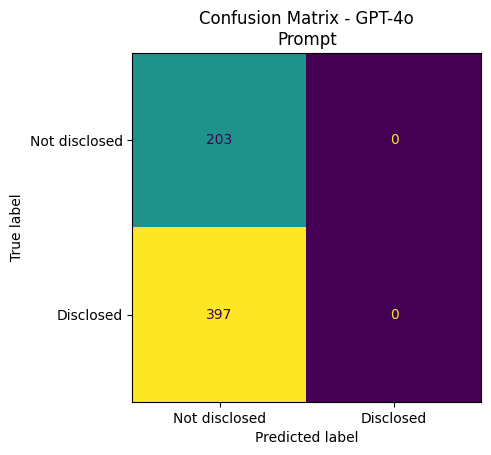

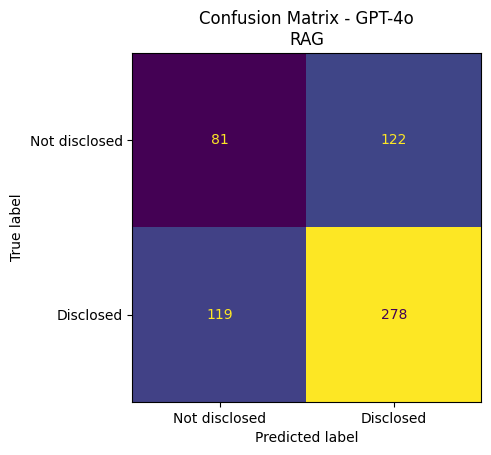

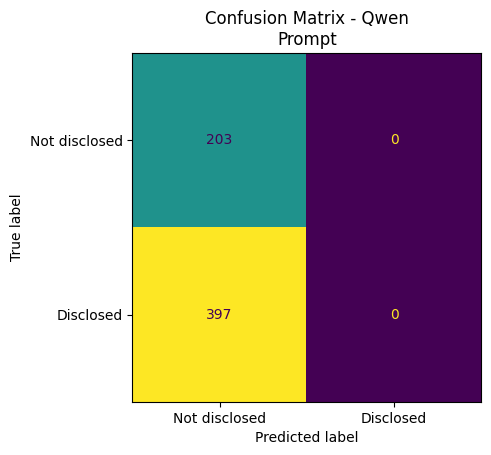

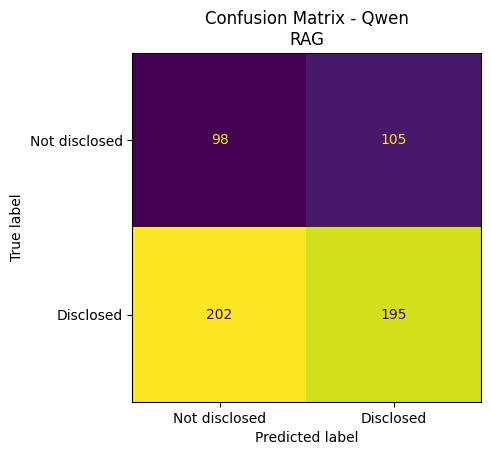

In [ ]:
for exp, g in eval_df.groupby("experiment"):
    y_true = g["is_disclosed"].astype(int)
    y_pred = g["pred_is_disclosed"].astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

    fig, ax = plt.subplots(figsize=(5, 5))
    from sklearn.metrics import ConfusionMatrixDisplay
    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Not disclosed", "Disclosed"]
    )
    disp.plot(ax=ax, colorbar=False)
    ax.set_title(f"Confusion Matrix - {label_map[exp]}")
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f"confusion_matrix_{exp}.png"), dpi=300)
    plt.show()

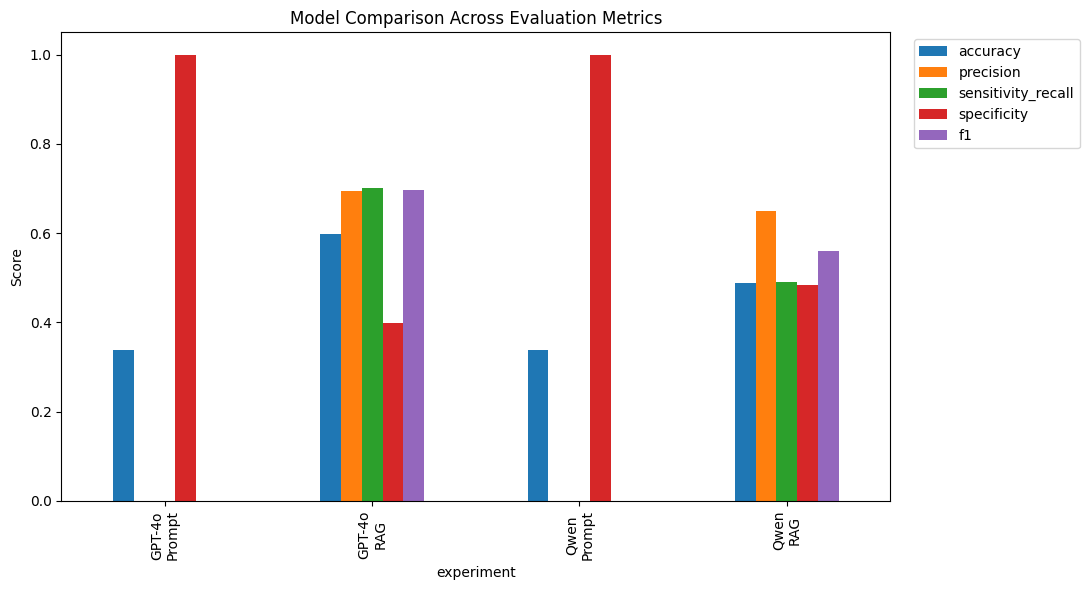

In [ ]:
metrics_to_plot = ["accuracy", "precision", "sensitivity_recall", "specificity", "f1"]
plot_df = summary_df.set_index("experiment")[metrics_to_plot]
plot_df.index = plot_df.index.map(label_map)

ax = plot_df.plot(kind="bar", figsize=(11, 6))
ax.set_title("Model Comparison Across Evaluation Metrics")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "model_comparison_metrics.png"), dpi=300)
plt.show()

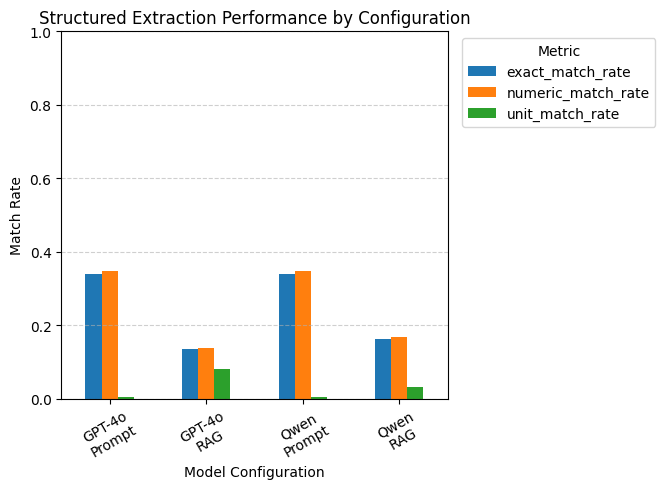

In [ ]:

plot_df = summary_df.set_index("experiment")[[
    "exact_match_rate",
    "numeric_match_rate",
    "unit_match_rate"
]]

plot_df.index = plot_df.index.map(label_map)

# Plot
ax = plot_df.plot(
    kind="bar",
    figsize=(8,5)
)

ax.set_title("Structured Extraction Performance by Configuration")
ax.set_ylabel("Match Rate")
ax.set_xlabel("Model Configuration")

plt.xticks(rotation=30)
plt.ylim(0,1)
plt.grid(axis='y', linestyle='--', alpha=0.6)


plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout(rect=[0, 0, 0.85, 1])
plt.savefig(os.path.join(FIG_DIR, "match_rate_comparison.png"), dpi=300)
plt.show()

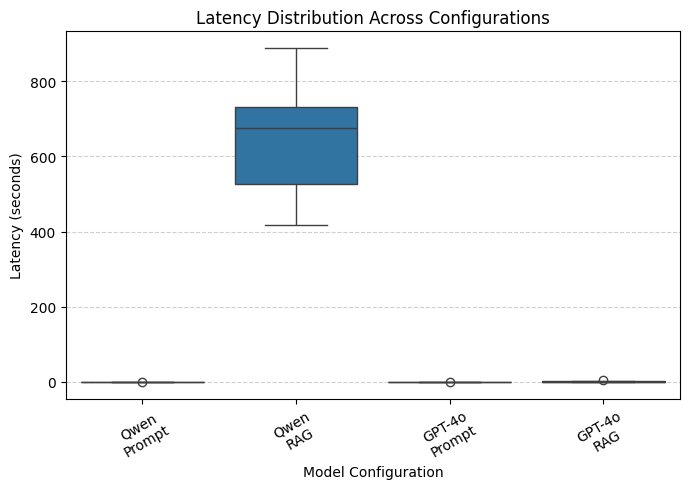

In [ ]:
import seaborn as sns

plt.figure(figsize=(7,5))

plot_data = combined_results_df.copy()
plot_data['mapped_experiment'] = plot_data['experiment'].map(label_map)

sns.boxplot(
    data=plot_data,  # long format: columns = ["experiment", "latency"]
    x="mapped_experiment",
    y="latency_sec"
)

plt.title("Latency Distribution Across Configurations")
plt.ylabel("Latency (seconds)")
plt.xlabel("Model Configuration")

plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "latency_distribution.png"), dpi=300)
plt.show()

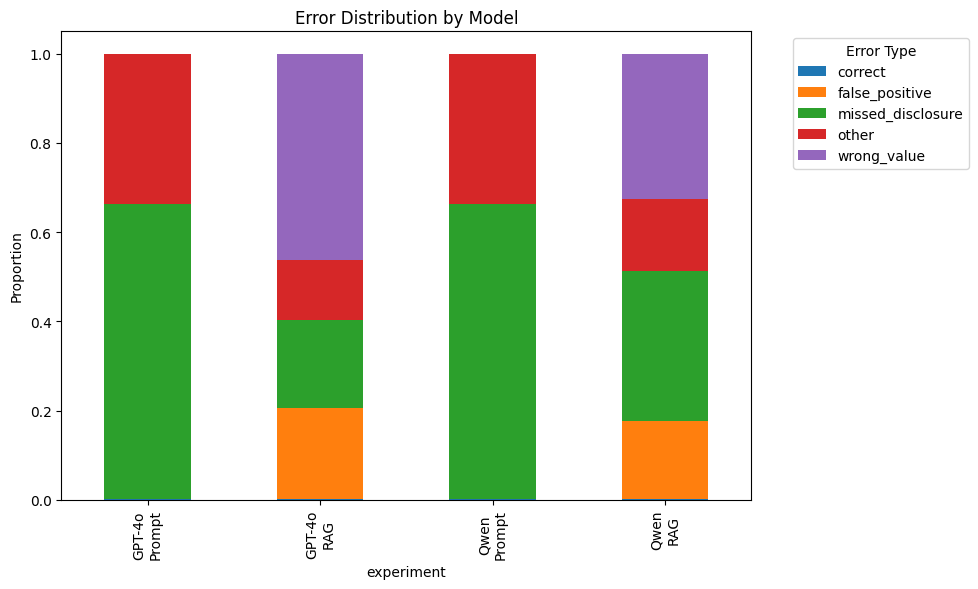

In [ ]:
plot_df = error_pivot.T
plot_df.index = plot_df.index.map(label_map)
ax = plot_df.plot(kind="bar", stacked=True, figsize=(10, 6))
ax.set_title("Error Distribution by Model")
ax.set_ylabel("Proportion")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "error_distribution.png"), dpi=300)
plt.legend(title="Error Type", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()